<a href="https://colab.research.google.com/github/amna-alii/CV-Lab05/blob/main/Lab05_HOG_Defect_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 05 — HOG-Based Industrial Defect Detection and Classification

## 1. Setup

In [ ]:
import os, glob, time, json, warnings, random
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET
from scipy.stats import binom

from skimage.feature import hog
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)
from sklearn.metrics.pairwise import euclidean_distances

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED); random.seed(SEED)
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
SUMMARY = {}          # key numbers, saved to results/summary.json at the end
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 130, "axes.grid": False})

## 2. Load and inspect the dataset (Task 1)

In [ ]:
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    import zipfile
    up = files.upload()                       # choose the NEU dataset zip
    zipfile.ZipFile(list(up)[0]).extractall("neu_data")
    DATA_ROOT = "neu_data"
else:
    DATA_ROOT = os.environ.get("NEU_ROOT", "neu_data")

# locate the folder that holds train_images / valid_images
for r, d, f in os.walk(DATA_ROOT):
    if "train_images" in d and "valid_images" in d:
        DATA_ROOT = r
        break
print("Dataset root:", DATA_ROOT)

Saving archive (5).zip to archive (5).zip
Dataset root: neu_data


In [ ]:
LIMIT = 0

def cls_of(p):
    return os.path.basename(p).rsplit("_", 1)[0]

def read_boxes(img_path):
    d = os.path.dirname(img_path)
    split = os.path.basename(d).replace("_images", "")
    xml = os.path.join(os.path.dirname(d), f"{split}_annotations", os.path.basename(img_path).replace(".jpg", ".xml"))
    root = ET.parse(xml).getroot()
    return [tuple(int(b.find(f"bndbox/{k}").text) for k in ("xmin", "ymin", "xmax", "ymax")) for b in root.findall("object")]

all_paths = sorted(glob.glob(f"{DATA_ROOT}/train_images/*.jpg") + glob.glob(f"{DATA_ROOT}/valid_images/*.jpg"))
if LIMIT:
    kept, cnt = [], {}
    for p in all_paths:
        c = cls_of(p); cnt[c] = cnt.get(c, 0) + 1
        if cnt[c] <= LIMIT: kept.append(p)
    all_paths = kept

CLASSES = sorted({cls_of(p) for p in all_paths})
y_all = np.array([CLASSES.index(cls_of(p)) for p in all_paths])
orig = np.stack([cv2.imread(p, cv2.IMREAD_GRAYSCALE) for p in all_paths])      # N x 200 x 200, uint8
boxes_all = [read_boxes(p) for p in all_paths]
official = np.array(["train" if "train_images" in p else "valid" for p in all_paths])
N = len(all_paths)
print(f"{N} images | shape {orig.shape[1:]} | classes: {CLASSES}")

rows = []
for ci, c in enumerate(CLASSES):
    idx = np.where(y_all == ci)[0]
    cover = []
    for i in idx:
        m = np.zeros(orig.shape[1:], bool)
        for x1, y1, x2, y2 in boxes_all[i]: m[y1:y2, x1:x2] = True
        cover.append(m.mean() * 100)
    rows.append({"Class": c, "Images": len(idx),
                 "Official train": int((official[idx] == "train").sum()),
                 "Official valid": int((official[idx] == "valid").sum()),
                 "Boxes / image": round(np.mean([len(boxes_all[i]) for i in idx]), 2),
                 "Defect-box coverage (%)": round(np.mean(cover), 1)})
dataset_df = pd.DataFrame(rows)
dataset_df.to_csv("results/dataset_summary.csv", index=False)
SUMMARY["n_images"] = int(N); SUMMARY["classes"] = CLASSES
dataset_df

1800 images | shape (200, 200) | classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


,Class,Images,Official train,Official valid,Boxes / image,Defect-box coverage (%)
0,crazing,300,283,17,2.31,50.0
1,inclusion,300,283,17,2.95,21.3
2,patches,300,284,16,2.91,36.0
3,pitted_surface,300,283,17,1.63,80.8
4,rolled-in_scale,300,283,17,2.09,29.9
5,scratches,300,284,16,2.07,17.9


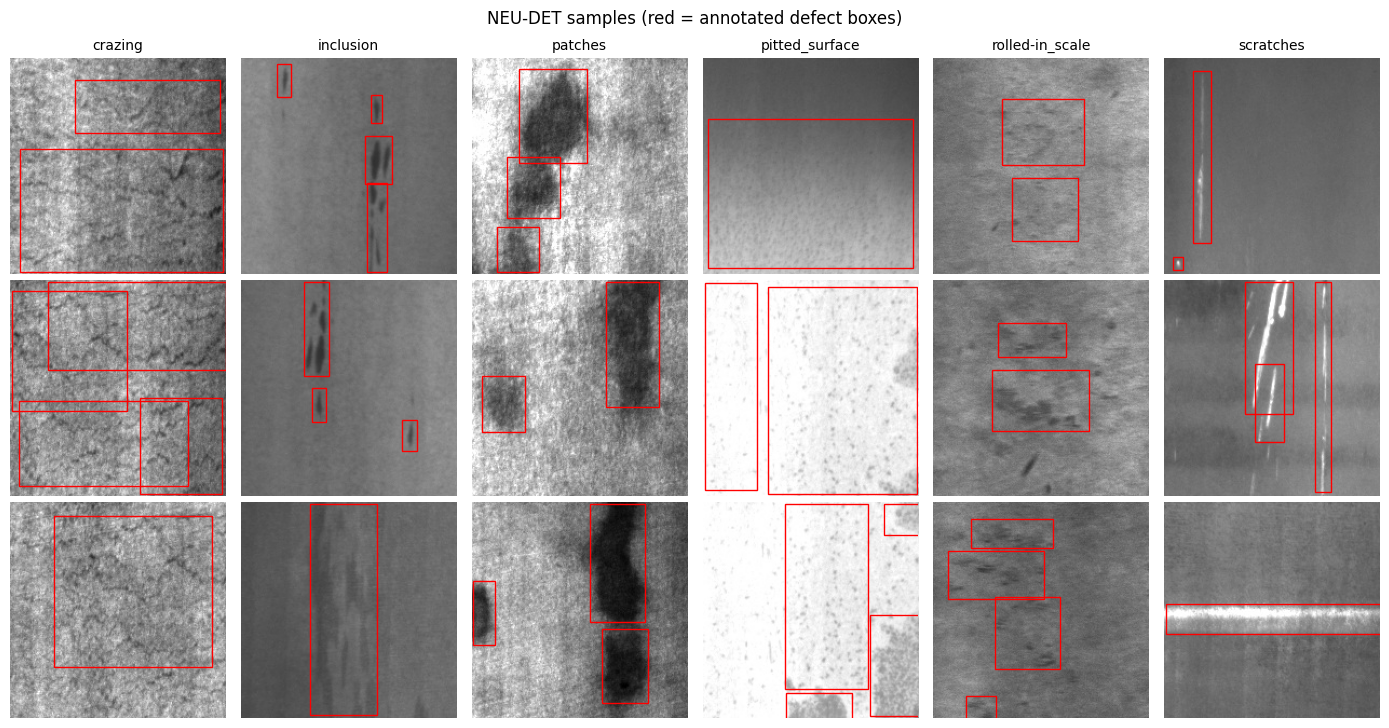

In [ ]:
fig, axes = plt.subplots(3, 6, figsize=(14, 7.4))
for ci, c in enumerate(CLASSES):
    idx = np.where(y_all == ci)[0][:3]
    for r, i in enumerate(idx):
        ax = axes[r, ci]; ax.imshow(orig[i], cmap="gray", vmin=0, vmax=255)
        for x1, y1, x2, y2 in boxes_all[i]:
            ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="red", lw=1))
        ax.axis("off")
        if r == 0: ax.set_title(c, fontsize=10)
plt.suptitle("NEU-DET samples (red = annotated defect boxes)")
plt.tight_layout(); plt.savefig("figures/fig1_dataset_samples.png"); plt.show()

## 3. Preprocessing and train / test split (Tasks 2–3)

Every image is converted to grayscale and resized to a common **128×128** resolution (area interpolation).
An optional *illumination normalisation* (per-image zero-mean / unit-variance stretch) is also provided and evaluated later in the robustness study.

We merge the official train and valid folders (1,800 images) and make one **stratified 80 / 20 split** (the official valid folder has only 100 images, too few for stable metrics).
Hyper-parameters are chosen with **3-fold cross-validation on the training part only**; the 20 % test set is used only for reporting.

In [ ]:
IMG_SIZE = 128

def preprocess(img, size=IMG_SIZE, normalize=False):
    g = img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)      # grayscale
    g = cv2.resize(g, (size, size), interpolation=cv2.INTER_AREA)            # common resolution
    if normalize:                                                            # optional illumination normalisation
        f = g.astype(np.float32)
        f = (f - f.mean()) / (f.std() + 1e-6)
        g = np.clip(f * 40 + 128, 0, 255).astype(np.uint8)
    return g

idx_train, idx_test = train_test_split(np.arange(N), test_size=0.2, stratify=y_all, random_state=SEED)
y_train, y_test = y_all[idx_train], y_all[idx_test]
print("train:", len(idx_train), "| test:", len(idx_test))
pre = np.stack([preprocess(i) for i in orig])          # N x 128 x 128

train: 1440 | test: 360


## 4. HOG feature extraction and visualisation (Tasks 4–5)

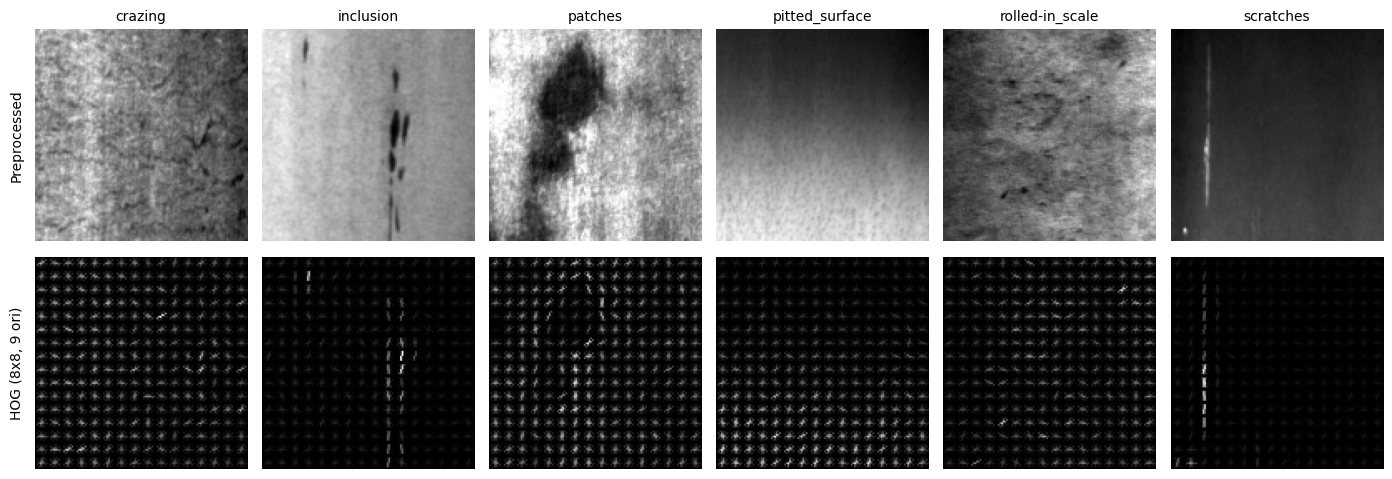

HOG vector length at 128x128, 8x8 cells, 9 orientations: 8100


In [ ]:
def hog_features(imgs, cell=8, ori=9, block=2):
    return np.stack([hog(i, orientations=ori, pixels_per_cell=(cell, cell), cells_per_block=(block, block),
                         block_norm="L2-Hys", feature_vector=True) for i in imgs]).astype(np.float32)

from skimage import exposure
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ci, c in enumerate(CLASSES):
    i = np.where(y_all == ci)[0][0]
    feat, vis = hog(pre[i], orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2),
                    block_norm="L2-Hys", visualize=True)
    axes[0, ci].imshow(pre[i], cmap="gray"); axes[0, ci].set_title(c, fontsize=10); axes[0, ci].axis("off")
    axes[1, ci].imshow(exposure.rescale_intensity(vis, in_range=(0, vis.max() + 1e-9)), cmap="gray"); axes[1, ci].axis("off")
axes[0, 0].text(-0.05, 0.5, "Preprocessed", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right")
axes[1, 0].text(-0.05, 0.5, "HOG (8x8, 9 ori)", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right")
plt.tight_layout(); plt.savefig("figures/fig2_hog_visualisation.png"); plt.show()
print("HOG vector length at 128x128, 8x8 cells, 9 orientations:", feat.shape[0])

## 5. HOG parameter study with SVM and a second classifier (Tasks 6, 7, 8, 11)

For every combination of **cell size ∈ {4, 8, 16}** × **orientations ∈ {6, 9, 12}** we train
* **HOG + SVM** (RBF kernel; `C ∈ {1, 10, 100}` chosen by 3-fold CV, using pre-computed kernels for speed), and
* **HOG + k-NN** (k = 5, cosine distance) as the additional classifier.

The best configuration is selected by **cross-validated SVM accuracy on the training set** (not on the test set).

In [ ]:
def gamma_scale(X):                      # same as sklearn gamma="scale"
    return 1.0 / (X.shape[1] * X.var())

def k_rbf(A, B, gamma):
    return np.exp(-gamma * euclidean_distances(A, B, squared=True))

def cv_select_C(K, y, Cs, folds=3):
    skf = StratifiedKFold(folds, shuffle=True, random_state=SEED)
    scores = {}
    for C in Cs:
        accs = []
        for a, b in skf.split(K, y):
            m = SVC(C=C, kernel="precomputed").fit(K[np.ix_(a, a)], y[a])
            accs.append(m.score(K[np.ix_(b, a)], y[b]))
        scores[C] = float(np.mean(accs))
    C = max(scores, key=scores.get)
    return C, scores[C]

def macro(y_true, y_pred):
    return dict(acc=accuracy_score(y_true, y_pred),
                prec=precision_score(y_true, y_pred, average="macro", zero_division=0),
                rec=recall_score(y_true, y_pred, average="macro", zero_division=0),
                f1=f1_score(y_true, y_pred, average="macro", zero_division=0))

CELLS, ORIS = (4, 8, 16), (6, 9, 12)
sweep_rows = []
for cell in CELLS:
    for ori in ORIS:
        t0 = time.time()
        F = hog_features(pre, cell, ori)
        t_ext = (time.time() - t0) / len(pre) * 1000
        Ftr, Fte = F[idx_train], F[idx_test]
        g = gamma_scale(Ftr)
        Ktr, Kte = k_rbf(Ftr, Ftr, g), k_rbf(Fte, Ftr, g)
        C, cv_acc = cv_select_C(Ktr, y_train, (1, 10, 100))
        svm = SVC(C=C, kernel="precomputed").fit(Ktr, y_train)
        m_svm = macro(y_test, svm.predict(Kte))
        knn = KNeighborsClassifier(n_neighbors=5, metric="cosine", algorithm="brute").fit(Ftr, y_train)
        m_knn = macro(y_test, knn.predict(Fte))
        sweep_rows.append({"Cell": f"{cell}x{cell}", "cell": cell, "Orientations": ori, "Feature dim": F.shape[1],
                           "HOG ms/img": round(t_ext, 1), "SVM C": C, "SVM CV acc": round(cv_acc, 4),
                           "SVM test acc": round(m_svm["acc"], 4), "SVM test F1": round(m_svm["f1"], 4),
                           "kNN test acc": round(m_knn["acc"], 4), "kNN test F1": round(m_knn["f1"], 4)})
        print(f"cell {cell:2d} ori {ori:2d} dim {F.shape[1]:6d} | SVM C={C:<3} CV={cv_acc:.3f} test={m_svm['acc']:.3f} | kNN test={m_knn['acc']:.3f}")
        del F, Ftr, Fte, Ktr, Kte

sweep_df = pd.DataFrame(sweep_rows)
sweep_df.drop(columns="cell").to_csv("results/hog_parameter_sweep.csv", index=False)
best = sweep_df.sort_values(["SVM CV acc", "Feature dim"], ascending=[False, True]).iloc[0]
BEST_CELL, BEST_ORI, BEST_C = int(best["cell"]), int(best["Orientations"]), best["SVM C"]
print(f"\nBest configuration by CV accuracy: cell {BEST_CELL}x{BEST_CELL}, {BEST_ORI} orientations, C={BEST_C}")
SUMMARY["best_cell"], SUMMARY["best_ori"], SUMMARY["best_C"] = BEST_CELL, BEST_ORI, float(BEST_C)
sweep_df.drop(columns="cell")

cell  4 ori  6 dim  23064 | SVM C=10  CV=0.815 test=0.817 | kNN test=0.619
cell  4 ori  9 dim  34596 | SVM C=10  CV=0.799 test=0.783 | kNN test=0.628
cell  4 ori 12 dim  46128 | SVM C=10  CV=0.831 test=0.817 | kNN test=0.675
cell  8 ori  6 dim   5400 | SVM C=10  CV=0.869 test=0.881 | kNN test=0.606
cell  8 ori  9 dim   8100 | SVM C=10  CV=0.867 test=0.856 | kNN test=0.625
cell  8 ori 12 dim  10800 | SVM C=10  CV=0.883 test=0.892 | kNN test=0.697
cell 16 ori  6 dim   1176 | SVM C=10  CV=0.895 test=0.911 | kNN test=0.725
cell 16 ori  9 dim   1764 | SVM C=10  CV=0.898 test=0.911 | kNN test=0.742
cell 16 ori 12 dim   2352 | SVM C=10  CV=0.916 test=0.931 | kNN test=0.778

Best configuration by CV accuracy: cell 16x16, 12 orientations, C=10


,Cell,Orientations,Feature dim,HOG ms/img,SVM C,SVM CV acc,SVM test acc,SVM test F1,kNN test acc,kNN test F1
0,4x4,6,23064,31.6,10,0.8153,0.8167,0.8130,0.6194,0.5887
1,4x4,9,34596,25.7,10,0.7986,0.7833,0.7767,0.6278,0.6081
2,4x4,12,46128,27.2,10,0.8306,0.8167,0.8132,0.6750,0.6426
3,8x8,6,5400,7.8,10,0.8694,0.8806,0.8788,0.6056,0.5590
4,8x8,9,8100,8.1,10,0.8667,0.8556,0.8529,0.6250,0.5797
5,8x8,12,10800,9.0,10,0.8833,0.8917,0.8909,0.6972,0.6406
6,16x16,6,1176,3.3,10,0.8951,0.9111,0.9101,0.7250,0.6968
7,16x16,9,1764,4.2,10,0.8979,0.9111,0.9103,0.7417,0.7078
8,16x16,12,2352,4.3,10,0.9160,0.9306,0.9302,0.7778,0.7363


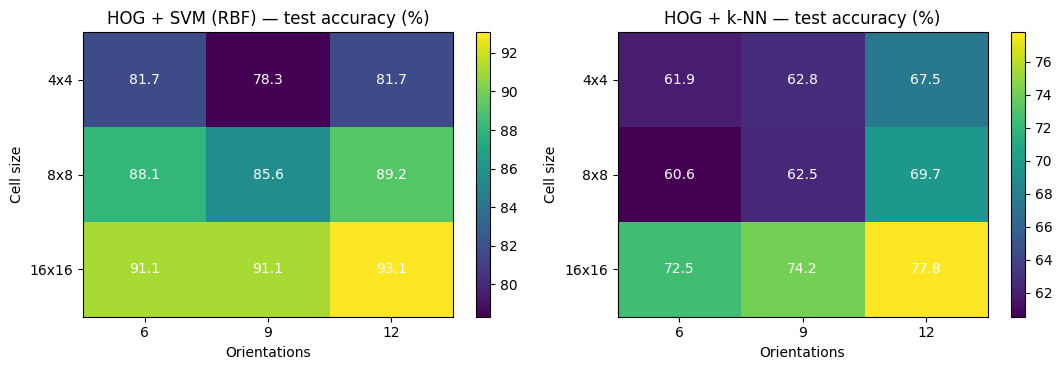

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, title in zip(axes, ["SVM test acc", "kNN test acc"], ["HOG + SVM (RBF)", "HOG + k-NN"]):
    M = sweep_df.pivot(index="Cell", columns="Orientations", values=col).loc[[f"{c}x{c}" for c in CELLS]]
    im = ax.imshow(M.values * 100, cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(ORIS))); ax.set_xticklabels(ORIS); ax.set_yticks(range(len(CELLS))); ax.set_yticklabels(M.index)
    ax.set_xlabel("Orientations"); ax.set_ylabel("Cell size"); ax.set_title(title + " — test accuracy (%)")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M.values[i, j]*100:.1f}", ha="center", va="center", color="w", fontsize=10)
    plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.savefig("figures/fig3_hog_parameter_heatmaps.png"); plt.show()

## 6. Classifier comparison, confusion matrix and classification report (Tasks 8–10)

At the best HOG configuration we compare **Linear SVM, RBF SVM, k-NN, Random Forest and Logistic Regression**.

In [ ]:
F = hog_features(pre, BEST_CELL, BEST_ORI)
Ftr, Fte = F[idx_train], F[idx_test]
g = gamma_scale(Ftr)
results, preds = [], {}

def timed_predict(model, X):
    t = time.time(); p = model.predict(X); return p, (time.time() - t) / len(X) * 1000

# Linear SVM (pre-computed linear kernel, C by CV)
Klin_tr, Klin_te = Ftr @ Ftr.T, Fte @ Ftr.T
C_lin, _ = cv_select_C(Klin_tr, y_train, (0.1, 1, 10))
t = time.time(); m = SVC(C=C_lin, kernel="precomputed").fit(Klin_tr, y_train); tt = time.time() - t
p = m.predict(Klin_te); preds["Linear SVM"] = p
results.append({"Classifier": "Linear SVM", **macro(y_test, p), "Train s": tt, "Predict ms/img": np.nan})

# RBF SVM — fitted with the real RBF kernel so it can be re-used for new images
t = time.time(); svm_rbf = SVC(C=BEST_C, kernel="rbf", gamma=g).fit(Ftr, y_train); tt = time.time() - t
p, ms = timed_predict(svm_rbf, Fte); preds["RBF SVM"] = p
results.append({"Classifier": "RBF SVM", **macro(y_test, p), "Train s": tt, "Predict ms/img": ms})

knn = KNeighborsClassifier(n_neighbors=5, metric="cosine", algorithm="brute")
t = time.time(); knn.fit(Ftr, y_train); tt = time.time() - t
p, ms = timed_predict(knn, Fte); preds["k-NN (k=5)"] = p
results.append({"Classifier": "k-NN (k=5)", **macro(y_test, p), "Train s": tt, "Predict ms/img": ms})

rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED)
t = time.time(); rf.fit(Ftr, y_train); tt = time.time() - t
p, ms = timed_predict(rf, Fte); preds["Random Forest"] = p
results.append({"Classifier": "Random Forest", **macro(y_test, p), "Train s": tt, "Predict ms/img": ms})

lr = LogisticRegression(C=10, max_iter=300)
t = time.time(); lr.fit(Ftr, y_train); tt = time.time() - t
p, ms = timed_predict(lr, Fte); preds["Logistic Regression"] = p
results.append({"Classifier": "Logistic Regression", **macro(y_test, p), "Train s": tt, "Predict ms/img": ms})

comp_df = pd.DataFrame(results).rename(columns={"acc": "Accuracy", "prec": "Precision", "rec": "Recall", "f1": "F1-score"})
for c in ["Accuracy", "Precision", "Recall", "F1-score"]: comp_df[c] = (comp_df[c] * 100).round(2)
comp_df[["Train s", "Predict ms/img"]] = comp_df[["Train s", "Predict ms/img"]].round(2)
comp_df.to_csv("results/classifier_comparison.csv", index=False)
SUMMARY["classifier_comparison"] = comp_df.to_dict(orient="records")
print(f"HOG config: cell {BEST_CELL}x{BEST_CELL}, {BEST_ORI} orientations | macro-averaged metrics (%)")
comp_df

HOG config: cell 16x16, 12 orientations | macro-averaged metrics (%)


,Classifier,Accuracy,Precision,Recall,F1-score,Train s,Predict ms/img
0,Linear SVM,87.22,87.41,87.22,87.01,0.03,NaN
1,RBF SVM,93.06,93.30,93.06,93.02,1.22,3.39
2,k-NN (k=5),77.78,84.11,77.78,73.63,0.00,0.34
3,Random Forest,90.00,90.24,90.00,89.91,11.72,0.22
4,Logistic Regression,81.11,80.85,81.11,80.81,12.92,0.03


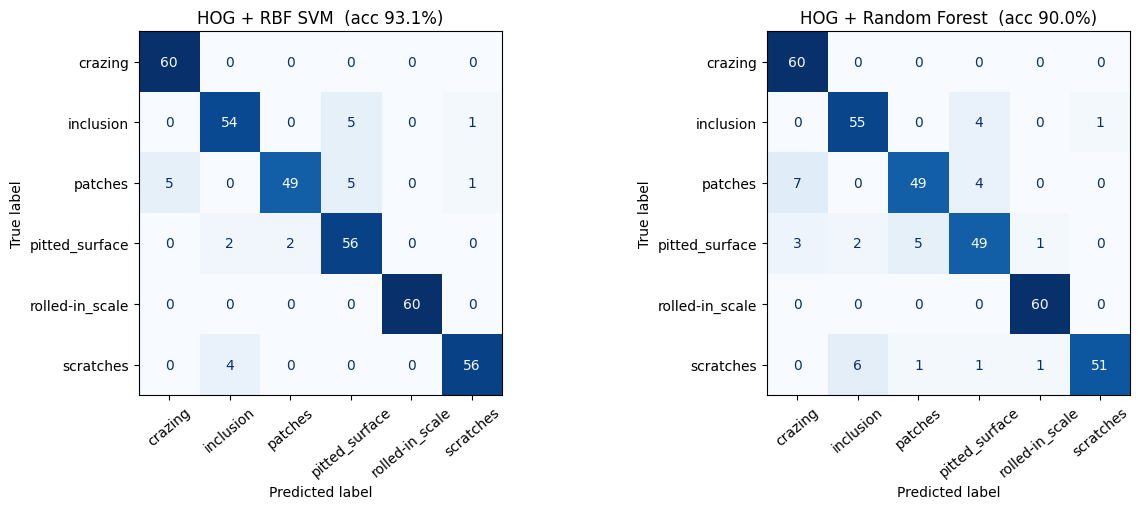

Classification report — HOG + RBF SVM

                 precision    recall  f1-score   support

        crazing      0.923     1.000     0.960        60
      inclusion      0.900     0.900     0.900        60
        patches      0.961     0.817     0.883        60
 pitted_surface      0.848     0.933     0.889        60
rolled-in_scale      1.000     1.000     1.000        60
      scratches      0.966     0.933     0.949        60

       accuracy                          0.931       360
      macro avg      0.933     0.931     0.930       360
   weighted avg      0.933     0.931     0.930       360



In [ ]:
other = comp_df[~comp_df["Classifier"].isin(["RBF SVM", "Linear SVM"])].sort_values("Accuracy", ascending=False).iloc[0]["Classifier"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, name in zip(axes, ["RBF SVM", other]):
    cm = confusion_matrix(y_test, preds[name])
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=40)
    ax.set_title(f"HOG + {name}  (acc {accuracy_score(y_test, preds[name])*100:.1f}%)")
plt.tight_layout(); plt.savefig("figures/fig4_confusion_matrices.png"); plt.show()

print("Classification report — HOG + RBF SVM\n")
rep = classification_report(y_test, preds["RBF SVM"], target_names=CLASSES, digits=3)
print(rep)
open("results/classification_report_svm.txt", "w").write(rep)
SUMMARY["svm_report"] = classification_report(y_test, preds["RBF SVM"], target_names=CLASSES, output_dict=True)
SUMMARY["other_classifier"] = other

## 7. Robustness study (Task 12)

The trained **HOG + RBF-SVM** is tested on perturbed copies of the *test* images (perturbation applied to the original 200×200 image, then the normal preprocessing + HOG).
Conditions: **brightness shift, Gaussian noise, rotation, Gaussian blur**, at several severities.
We compare the baseline pipeline with one that adds **illumination normalisation** (re-trained) to see whether a simple preprocessing step improves robustness.

In [ ]:
def p_brightness(img, delta, rng=None): return np.clip(img.astype(np.int16) + delta, 0, 255).astype(np.uint8)
def p_noise(img, sigma, rng): return np.clip(img.astype(np.float32) + rng.normal(0, sigma, img.shape), 0, 255).astype(np.uint8)
def p_rotate(img, ang, rng=None):
    h, w = img.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), ang, 1.0)
    return cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
def p_blur(img, sigma, rng=None): return cv2.GaussianBlur(img, (0, 0), sigma)

CONDITIONS = [("Clean", None, 0)] + \
    [("Brightness", p_brightness, d) for d in (-60, -30, 30, 60)] + \
    [("Gaussian noise", p_noise, s) for s in (5, 15, 30)] + \
    [("Rotation", p_rotate, a) for a in (5, 15, 30)] + \
    [("Blur", p_blur, s) for s in (1, 2, 3)]
LEVEL_UNIT = {"Brightness": "", "Gaussian noise": "sigma=", "Rotation": "deg=", "Blur": "sigma=", "Clean": ""}

def eval_pipeline(model, normalize):
    out = []
    for name, fn, lvl in CONDITIONS:
        rng = np.random.default_rng(SEED)
        raw = orig[idx_test] if fn is None else np.stack([fn(i, lvl, rng) for i in orig[idx_test]])
        X = hog_features([preprocess(i, normalize=normalize) for i in raw], BEST_CELL, BEST_ORI)
        out.append(macro(y_test, model.predict(X)))
    return out

res_base = eval_pipeline(svm_rbf, normalize=False)

# pipeline with illumination normalisation (re-trained on normalised training images)
pre_n = np.stack([preprocess(i, normalize=True) for i in orig])
Fn = hog_features(pre_n, BEST_CELL, BEST_ORI)
svm_norm = SVC(C=BEST_C, kernel="rbf", gamma=gamma_scale(Fn[idx_train])).fit(Fn[idx_train], y_train)
res_norm = eval_pipeline(svm_norm, normalize=True)

rob_rows = []
for (name, fn, lvl), rb, rn in zip(CONDITIONS, res_base, res_norm):
    rob_rows.append({"Condition": name, "Level": f"{LEVEL_UNIT[name]}{lvl}" if name != "Clean" else "-",
                     "Acc (%)": rb["acc"] * 100, "F1 (%)": rb["f1"] * 100,
                     "dAcc": (rb["acc"] - res_base[0]["acc"]) * 100, "dF1": (rb["f1"] - res_base[0]["f1"]) * 100,
                     "Acc +norm (%)": rn["acc"] * 100, "F1 +norm (%)": rn["f1"] * 100,
                     "dAcc +norm": (rn["acc"] - res_norm[0]["acc"]) * 100})
rob_df = pd.DataFrame(rob_rows).round(2)
rob_df.to_csv("results/robustness_results.csv", index=False)
SUMMARY["robustness"] = rob_df.to_dict(orient="records")
rob_df

,Condition,Level,Acc (%),F1 (%),dAcc,dF1,Acc +norm (%),F1 +norm (%),dAcc +norm
0,Clean,-,93.06,93.02,0.00,0.00,91.67,91.62,0.00
1,Brightness,-60,90.56,90.64,-2.50,-2.37,88.89,88.98,-2.78
2,Brightness,-30,93.89,93.84,0.83,0.82,92.78,92.75,1.11
3,Brightness,30,86.67,86.61,-6.39,-6.41,85.83,85.66,-5.83
4,Brightness,60,77.50,76.98,-15.56,-16.03,77.50,76.96,-14.17
5,Gaussian noise,sigma=5,77.50,76.35,-15.56,-16.66,77.78,76.90,-13.89
6,Gaussian noise,sigma=15,41.67,35.39,-51.39,-57.62,42.78,36.35,-48.89
7,Gaussian noise,sigma=30,19.72,9.44,-73.33,-83.57,19.44,9.29,-72.22
8,Rotation,deg=5,92.22,92.26,-0.83,-0.76,92.50,92.53,0.83
9,Rotation,deg=15,90.00,90.04,-3.06,-2.98,88.33,88.49,-3.33


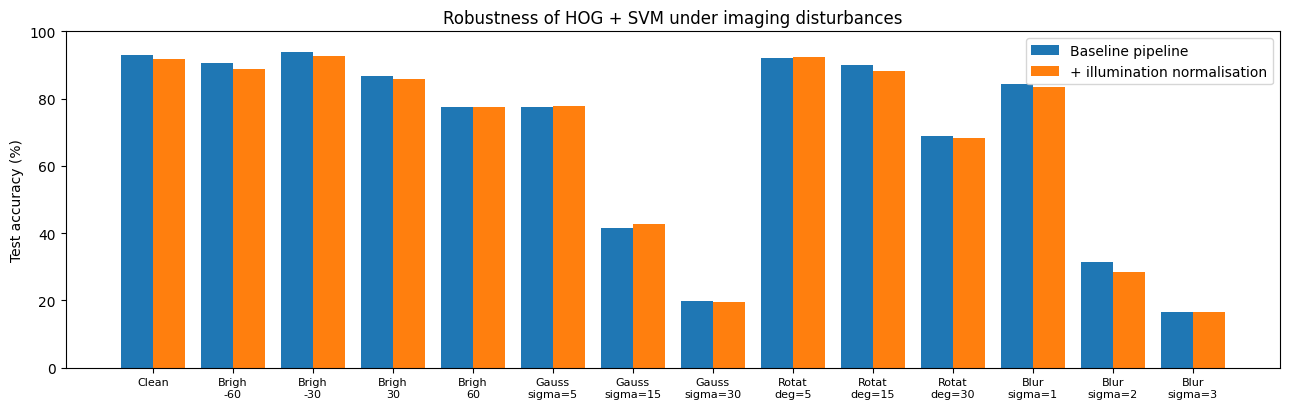

In [ ]:
labels = [f"{r['Condition'][:5]}\n{r['Level']}" if r["Condition"] != "Clean" else "Clean" for _, r in rob_df.iterrows()]
x = np.arange(len(rob_df)); w = 0.4
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.bar(x - w/2, rob_df["Acc (%)"], w, label="Baseline pipeline")
ax.bar(x + w/2, rob_df["Acc +norm (%)"], w, label="+ illumination normalisation")
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8); ax.set_ylabel("Test accuracy (%)")
ax.set_ylim(0, 100); ax.legend(); ax.set_title("Robustness of HOG + SVM under imaging disturbances")
plt.tight_layout(); plt.savefig("figures/fig5_robustness.png"); plt.show()

## 8. Stage B — binary defect / defect-free detector (Task 13 preparation)

Because NEU-DET has no normal images, we build **64×64 patches** from the annotations:
* **Defective patch** — a window fully inside an annotated defect box.
* **Defect-free patch** — a window that **does not overlap any annotated box**.

Patches are cut **per image after the image-level train / test split** (no image contributes patches to both sets), and classes are balanced by random down-sampling.

patch sets — train: 4464 (2232 defective / 2232 defect-free) | test: 1146


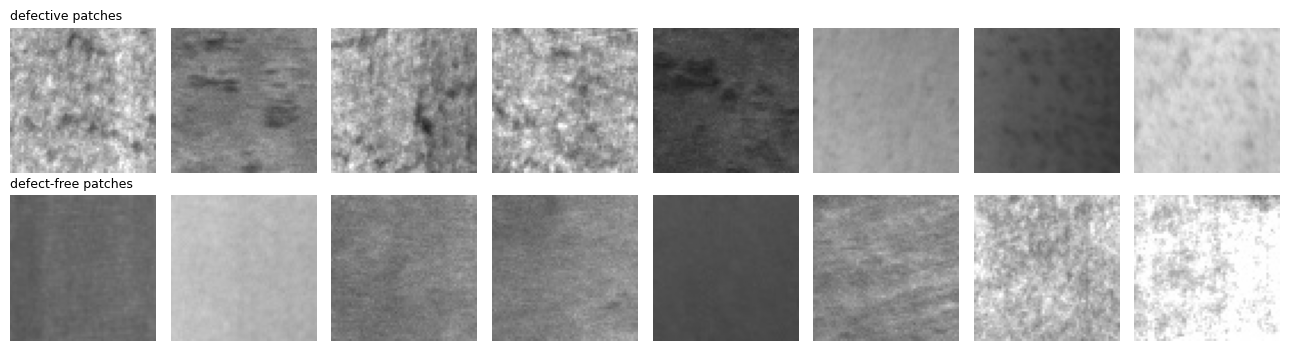

In [ ]:
PATCH = 64
rng = np.random.default_rng(SEED)

def box_mask(shape, boxes):
    m = np.zeros(shape, bool)
    for x1, y1, x2, y2 in boxes: m[y1:y2, x1:x2] = True
    return m

def sample_patches(i, n_def=3, n_norm=3):
    img, boxes = orig[i], boxes_all[i]
    mask = box_mask(img.shape, boxes)
    H, W = img.shape
    d, nrm = [], []
    cand = [b for b in boxes if (b[2] - b[0]) >= PATCH and (b[3] - b[1]) >= PATCH]
    for _ in range(n_def if cand else 0):
        x1, y1, x2, y2 = cand[rng.integers(len(cand))]
        x = rng.integers(x1, x2 - PATCH + 1); y = rng.integers(y1, y2 - PATCH + 1)
        d.append(img[y:y + PATCH, x:x + PATCH])
    tries = 0
    while len(nrm) < n_norm and tries < 80:
        x = rng.integers(0, W - PATCH + 1); y = rng.integers(0, H - PATCH + 1)
        if not mask[y:y + PATCH, x:x + PATCH].any(): nrm.append(img[y:y + PATCH, x:x + PATCH])
        tries += 1
    return d, nrm

def build_patch_set(indices):
    D, Nn, DC = [], [], []
    for i in indices:
        d, nrm = sample_patches(i)
        D += d; DC += [y_all[i]] * len(d); Nn += nrm
    n = min(len(D), len(Nn))
    pd_idx = rng.permutation(len(D))[:n]; pn_idx = rng.permutation(len(Nn))[:n]
    X = np.stack([D[k] for k in pd_idx] + [Nn[k] for k in pn_idx])
    y = np.array([1] * n + [0] * n)
    return X, y, np.array([DC[k] for k in pd_idx])

Xp_tr, yp_tr, _ = build_patch_set(idx_train)
Xp_te, yp_te, dcls_te = build_patch_set(idx_test)
print(f"patch sets — train: {len(yp_tr)} ({yp_tr.sum()} defective / {(yp_tr==0).sum()} defect-free) | test: {len(yp_te)}")

fig, axes = plt.subplots(2, 8, figsize=(13, 3.6))
for j in range(8):
    axes[0, j].imshow(Xp_tr[yp_tr == 1][j * 7], cmap="gray", vmin=0, vmax=255); axes[0, j].axis("off")
    axes[1, j].imshow(Xp_tr[yp_tr == 0][j * 7], cmap="gray", vmin=0, vmax=255); axes[1, j].axis("off")
axes[0, 0].set_title("defective patches", fontsize=9, loc="left"); axes[1, 0].set_title("defect-free patches", fontsize=9, loc="left")
plt.tight_layout(); plt.savefig("figures/fig6_patch_examples.png"); plt.show()

In [ ]:
# choose HOG cell size for patches by 3-fold CV (orientations fixed at 9)
patch_rows = []
for cell in (4, 8, 16):
    Ftr_p = hog_features(Xp_tr, cell, 9)
    Ktr_p = k_rbf(Ftr_p, Ftr_p, gamma_scale(Ftr_p))
    C_p, cv_p = cv_select_C(Ktr_p, yp_tr, (1, 10, 100))
    patch_rows.append({"cell": cell, "C": C_p, "cv": cv_p, "dim": Ftr_p.shape[1]})
    print(f"patch HOG cell {cell:2d} dim {Ftr_p.shape[1]:5d} | CV acc {cv_p:.3f} (C={C_p})")
bp = max(patch_rows, key=lambda r: r["cv"])
P_CELL, P_C = bp["cell"], bp["C"]

Fp_tr, Fp_te = hog_features(Xp_tr, P_CELL, 9), hog_features(Xp_te, P_CELL, 9)
det_svm = SVC(C=P_C, kernel="rbf", gamma=gamma_scale(Fp_tr), probability=True, random_state=SEED).fit(Fp_tr, yp_tr)
det_rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED).fit(Fp_tr, yp_tr)

patch_res = []
for name, m in [("HOG + SVM (RBF)", det_svm), ("HOG + Random Forest", det_rf)]:
    p = m.predict(Fp_te)
    tn, fp, fn, tp = confusion_matrix(yp_te, p).ravel()
    patch_res.append({"Classifier": name, "Accuracy": accuracy_score(yp_te, p) * 100,
                      "Precision": precision_score(yp_te, p) * 100, "Recall": recall_score(yp_te, p) * 100,
                      "F1-score": f1_score(yp_te, p) * 100, "False-alarm rate (defect-free flagged)": fp / (fp + tn) * 100})
patch_df = pd.DataFrame(patch_res).round(2)
patch_df.to_csv("results/binary_patch_results.csv", index=False)
SUMMARY["binary_patch"] = patch_df.to_dict(orient="records"); SUMMARY["patch_cell"] = P_CELL
print(f"\nBinary patch detector: HOG cell {P_CELL}x{P_CELL}, 9 orientations, 64x64 patches")
patch_df

patch HOG cell  4 dim  8100 | CV acc 0.735 (C=1)
patch HOG cell  8 dim  1764 | CV acc 0.736 (C=10)
patch HOG cell 16 dim   324 | CV acc 0.765 (C=10)

Binary patch detector: HOG cell 16x16, 9 orientations, 64x64 patches


,Classifier,Accuracy,Precision,Recall,F1-score,False-alarm rate (defect-free flagged)
0,HOG + SVM (RBF),74.17,72.97,76.79,74.83,28.45
1,HOG + Random Forest,71.90,71.31,73.30,72.29,29.49


## 9. Industrial quality-control decision module (Task 13)

`inspect_product(image)` scans the image with overlapping 64×64 windows (5×5 = 25 windows on a 200×200 image), asks the binary detector for P(defect) in every window,
and **rejects the product if at least *k* windows are flagged**. If rejected, the whole-image 6-class model names the **defect type**.

*Choosing k.* We have no real defect-free full images, so the false-reject rate cannot be measured directly. As an estimate we use the detector's false-alarm rate on held-out defect-free patches and a
binomial model (25 windows) to choose the smallest *k* with an estimated false-reject probability ≤ 5 %. Overlapping windows are not independent, so this is an approximation.

In [ ]:
N_WIN = 5          # 5 x 5 windows on a 200 x 200 image
fa_rate = max(patch_df.iloc[0]["False-alarm rate (defect-free flagged)"] / 100, 0.5 / (yp_te == 0).sum())
K_REJECT = next((k for k in range(1, N_WIN * N_WIN + 1) if binom.sf(k - 1, N_WIN * N_WIN, fa_rate) <= 0.05), N_WIN * N_WIN)
TAU = K_REJECT / (N_WIN * N_WIN)
print(f"patch false-alarm rate {fa_rate*100:.1f}% -> reject if >= {K_REJECT} of 25 windows flagged (fraction >= {TAU:.2f})")

# whole-image 6-class model with probabilities (for the defect-type report)
type_model = SVC(C=BEST_C, kernel="rbf", gamma=gamma_scale(Ftr), probability=True, random_state=SEED).fit(Ftr, y_train)

def window_positions(L):
    return [0] if L <= PATCH else list(np.linspace(0, L - PATCH, N_WIN).astype(int))

def scan(img):
    H, W = img.shape
    wins, coords = [], []
    for y in window_positions(H):
        for x in window_positions(W):
            wins.append(img[y:y + PATCH, x:x + PATCH]); coords.append((x, y))
    p_def = det_svm.predict_proba(hog_features(wins, P_CELL, 9))[:, 1]
    return np.array(coords), p_def

def inspect_product(img, verbose=True):
    coords, p_def = scan(img)
    flagged = p_def >= 0.5
    frac = flagged.mean()
    defective = frac >= TAU
    if defective:
        conf = p_def[flagged].mean() * 100
        probs = type_model.predict_proba(hog_features([preprocess(img)], BEST_CELL, BEST_ORI))[0]
        dtype, dconf = CLASSES[int(np.argmax(probs))], probs.max() * 100
    else:
        conf, dtype, dconf = (1 - p_def).mean() * 100, None, None
    out = dict(defective=bool(defective), confidence=conf, flagged=int(flagged.sum()), windows=len(flagged),
               defect_type=dtype, type_confidence=dconf, coords=coords, flags=flagged)
    if verbose:
        print("PRODUCT INSPECTION RESULT")
        print(f"Prediction: {'DEFECTIVE' if defective else 'NON-DEFECTIVE'}")
        print(f"Confidence: {conf:.1f}%")
        print(f"Action: {'REJECT PRODUCT' if defective else 'ACCEPT PRODUCT'}")
        print(f"(flagged windows: {out['flagged']}/{out['windows']}" + (f" | likely defect type: {dtype} {dconf:.0f}%)" if defective else ")"))
    return out

patch false-alarm rate 28.4% -> reject if >= 12 of 25 windows flagged (fraction >= 0.48)


In [ ]:
# image-level evaluation on the held-out test images (all of them contain defects)
t0 = time.time()
flag_frac = []
for i in idx_test:
    _, p = scan(orig[i]); flag_frac.append((p >= 0.5).mean())
flag_frac = np.array(flag_frac)
insp_ms = (time.time() - t0) / len(idx_test) * 1000
detected = flag_frac >= TAU
det_by_class = pd.DataFrame({"Class": [CLASSES[c] for c in y_test], "Rejected": detected}).groupby("Class")["Rejected"].mean().mul(100).round(1)
print(f"Image-level defect detection (test images, k>={K_REJECT}/25): {detected.mean()*100:.1f}%  | scan time {insp_ms:.0f} ms/image")
print("\nDetection rate by defect class (%):"); print(det_by_class.to_string())
SUMMARY.update(K_REJECT=int(K_REJECT), image_detection_rate=float(detected.mean() * 100), inspect_ms=float(insp_ms),
               det_by_class=det_by_class.to_dict(), patch_false_alarm=float(fa_rate * 100))
det_by_class.to_csv("results/image_level_detection_by_class.csv")

In [ ]:
# demonstration: 3 defective test images + 1 held-out defect-free patch
demo = [(orig[idx_test[np.where(y_test == c)[0][0]]], CLASSES[c]) for c in (5, 2, 0)]
demo.append((Xp_te[yp_te == 0][3], "defect-free patch"))
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, (im, tag) in zip(axes, demo):
    r = inspect_product(im, verbose=False)
    ax.imshow(im, cmap="gray", vmin=0, vmax=255); ax.axis("off")
    for (x, y), f in zip(r["coords"], r["flags"]):
        if f: ax.add_patch(plt.Rectangle((x, y), PATCH, PATCH, fill=False, ec="red", lw=1))
    verdict = "REJECT" if r["defective"] else "ACCEPT"
    ax.set_title(f"{tag}\n{verdict} ({r['confidence']:.0f}%)  {r['flagged']}/{r['windows']} windows", fontsize=9,
                 color="red" if r["defective"] else "green")
plt.tight_layout(); plt.savefig("figures/fig7_decision_module.png"); plt.show()

print("=== Example 1: defective product ==="); inspect_product(demo[0][0])
print("\n=== Example 2: defect-free sample (64x64 crop) ==="); inspect_product(demo[3][0])

## 10. Save results and models

In [ ]:
import joblib
os.makedirs("models", exist_ok=True)
joblib.dump({"model": det_svm, "cell": P_CELL, "orientations": 9, "patch": PATCH, "tau": TAU, "k": int(K_REJECT)},
            "models/binary_patch_svm.joblib", compress=3)
print("saved binary detector:", round(os.path.getsize("models/binary_patch_svm.joblib") / 1e6, 1), "MB")
json.dump(SUMMARY, open("results/summary.json", "w"), indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Summary saved. Figures:", sorted(os.listdir("figures")))
if IN_COLAB:
    import shutil
    shutil.make_archive("lab05_outputs", "zip", ".", "results"); files.download("lab05_outputs.zip")

## Limitations
* NEU-DET has no real defect-free images; the "defect-free" class in Stage B is derived from **un-annotated regions**, which may still contain faint defect texture (especially for *crazing* and *pitted_surface*, whose boxes cover most of the image).
* The ACCEPT threshold *k* is calibrated from patch-level false alarms, not from real normal products, so the true false-reject rate on a production line is unknown.
* Results come from a single stratified split (seed 42) on one steel-surface dataset and a fixed lighting setup.